# Predicting apartment sale prices in Astana and Almaty from krisha.kz listings

**Course project, Midterm (Week 5)** · Machine Learning Algorithms · Group **SE-2424**
**Team:** Rakhat Balgabekov, Aitbek Kaiyrbekuly
**Direction:** 1. Apartments for sale · **Task:** regression · **Target:** apartment sale price (KZT)

## 1. Question

**How accurately can we predict the asking sale price (KZT) of an apartment in Astana or Almaty from its listing characteristics** — total area, number of rooms, floor and total floors, building type, year built, district, condition and other attributes?

**Why it matters and who uses the answer.** Asking prices on listing sites are set by sellers and often differ from the market value of similar apartments.
- a **buyer** can check whether an asking price is fair before viewing or negotiating;
- a **seller** can set a realistic price so the apartment does not stay unsold for months;
- a **realtor** gets a quick reference estimate for a new listing.

**Main metric.** The question is about the size of the error in money, so the main metric is **MAE in KZT** on the held-out test set. The ideal goal in our registration is formulated as a relative error ("median error under 10 %"), so we also report the **median absolute percentage error (MdAPE)**. RMSE and R² are reported for completeness; RMSE is dominated by a handful of very expensive apartments, which is exactly why it is not the main metric.

## 2. Data card

| Item | Value |
|---|---|
| Source | krisha.kz, section *Продажа квартир*: `https://krisha.kz/prodazha/kvartiry/astana/` and `.../almaty/` |
| Additional sources from the registration (olx.kz, kn.kz) | not used: krisha.kz alone gave more rows than the 3,000 we promised, so the cross-site matching rule from the registration was not needed; the same rule (city, street, house, rooms, floor, area, price within 5 %) is applied *within* krisha.kz to remove reposts (cleaning step 3) |
| What one row describes | One apartment-for-sale advertisement (one listing id) in Astana or Almaty |
| How collected | Our own scraper `data_collection/scrape_krisha.py` (requests + BeautifulSoup). Stage 1 walks the search result pages (20 ads per page) and stores every ad card; stage 2 opens the mobile ad page `m.krisha.kz/a/show/<id>` and stores the structured parameters, the description text and photo URLs. One request at a time, 0.6–1.2 s pause between requests. |
| When collected | search pages and the first half of the ad pages on 4 October 2026; the second half of the ad pages on 8 October 2026, after the site's bot challenge had lifted (exact UTC timestamps in `data/raw/collection_log.json`, the stage logs and the `scraped_at` field of every raw row) |
| Raw snapshot | `data/raw/listings_raw.jsonl` (search cards), `data/raw/details_raw.jsonl` (ad pages), plus sample HTML pages in `data/raw/html_sample/` |
| Rows | see the counts printed below: raw → after cleaning. The full ad page was opened for all but a handful of ads; the few ads removed from the site between 4 and 8 October fall back to their search card (`has_detail` flag, section 3.1b) |
| Text field for the Final | `description` (seller's free text), photo URLs in `photo_urls` |
| Source check | `robots.txt` (checked 4 Oct 2026) disallows only service paths (`/ajax/`, `/comments`, `/claim`, map and search-parameter URLs); the listing pages `/prodazha/...` and ad pages `/a/show/...` are allowed. No login is needed. The data describe objects (apartments), not private people: we do **not** store the seller's name, phone or account id. Developer ads with a "от …" (from) price are skipped because they have no fixed asking price. |

### Fields (after parsing, before cleaning)

| Field | Type | Meaning | Origin |
|---|---|---|---|
| `id` | int | krisha.kz listing id | card `data-id` |
| `city` | category | Astana / Almaty | search URL |
| `district` | category | city district (*район*) | ad JSON `address.district` |
| `street`, `house_num` | text | address as typed by the seller (used only for duplicate detection) | ad JSON |
| `lat`, `lon` | float | map coordinates of the ad | ad JSON `map` |
| `price` | int | **target**, asking price in KZT | ad JSON `price` |
| `rooms` | int | number of rooms | ad JSON |
| `area` | float | total area, m² (`log_area` is derived from it for the models) | ad JSON `square` |
| `kitchen_area` | float | kitchen area, m² (often missing) | *Площадь* line |
| `floor`, `total_floors` | int | floor of the apartment and floors in the building | *Этаж* line |
| `year_built` | int | year the building was built | *Год постройки* |
| `building_type` | category | monolithic / brick / panel / other | *Тип дома* |
| `condition` | category | renovation state (*свежий ремонт*, *среднее*, *требует ремонта*, …) | *Состояние* |
| `bathroom` | category | combined / separate / 2+ | *Санузел* |
| `ceiling_height` | float | ceiling height, m | *Высота потолков* |
| `furnished` | category | fully / partly / no | *Квартира меблирована* |
| `balcony`, `parking`, `former_dorm`, `has_complex`, `mortgaged`, `exchange_possible` | category / bool | other listing attributes | parameters block |
| `seller_type` | category | owner / specialist (agent) / company | ad JSON `userType` |
| `n_photos` | int | number of photos in the ad | ad JSON |
| `description` | text | seller's free text (kept for the Final, **not** used as a feature now) | ad page |
| `scraped_at` | datetime | collection timestamp (UTC) | scraper |

In [1]:
import json, re, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
FIG = Path("figures"); FIG.mkdir(exist_ok=True)
SEED = 42
rng = np.random.default_rng(SEED)

## 3. Loading the raw snapshot

In [2]:
RAW = Path("data/raw")
listings = pd.read_json(RAW / "listings_raw.jsonl", lines=True)
details  = pd.read_json(RAW / "details_raw.jsonl",  lines=True)
log = json.loads((RAW / "collection_log.json").read_text())
print("collection runs:")
for r in log: print("  ", r["stage"], r["started_utc"])
print(f"\nsearch cards collected : {len(listings):,}  ({listings.city_slug.value_counts().to_dict()})")
print(f"ad pages collected     : {len(details):,}")
print(f"ad pages that failed   : {details.get('fetch_error', pd.Series(dtype=bool)).fillna(False).sum()}")
listings.head(3)

collection runs:
   listings 2026-10-04T17:02:20+00:00
   listings 2026-10-04T17:03:48+00:00
   details 2026-10-04T17:09:24+00:00
   details 2026-10-04T17:11:53+00:00
   details 2026-10-08T12:45:26+00:00
   details 2026-10-08T12:46:38+00:00
   details 2026-10-08T13:00:06+00:00

search cards collected : 5,810  ({'astana': 3194, 'almaty': 2616})
ad pages collected     : 4,822
ad pages that failed   : 13.0


,id,city_slug,title,price_text,subtitle,preview_text,stats,owner_label,is_urgent,is_hot,image_url,url,scraped_at,page
0,1014932041,astana,3-комнатная квартира · 108.2 м²,от 50 854 000 ₸,"Сарайшык р-н, Нажимеденова 15/1","жил. комплекс Beles Park, 16 этажей, 2027 г.п....","[Астана, 4 окт., ]",NaN,False,False,https://krisha-photos.kcdn.online/webp/f9/f946...,https://krisha.kz/a/show/1014932041,2026-10-04 17:02:21+00:00,1
1,1013229676,astana,1-комнатная квартира · 43.26 м²,от 21 984 732 ₸,"Сарайшык р-н, Ахмет Байтурсынулы 16/1","жил. комплекс Qasiet City, 16 этажей, 2027 г.п...","[Астана, 4 окт., ]",NaN,False,False,https://krisha-photos.kcdn.online/webp/a4/a440...,https://krisha.kz/a/show/1013229676,2026-10-04 17:02:21+00:00,1
2,1004699268,astana,2-комнатная квартира · 63.89 м²,от 47 243 989 ₸,"Нура р-н, Е 908 23","жил. комплекс UIA.BIRLIK, 17 этажей, 2027 г.п....","[Астана, 4 окт., ]",NaN,False,False,https://krisha-photos.kcdn.online/webp/de/debc...,https://krisha.kz/a/show/1004699268,2026-10-04 17:02:21+00:00,1


### 3.1 Parsing the raw strings into typed fields
Everything on krisha.kz is a string ("5 из 17", "35 м², Площадь кухни — 9.72 м²", "3 м"). We parse with regular expressions and keep the raw columns next to the parsed ones so every parsing step can be checked.

In [3]:
def num(s, pat=r"([\d]+(?:[.,]\d+)?)"):
    if isinstance(s, (int, float, np.integer, np.floating)): return float(s)   # read_json already typed it
    if not isinstance(s, str): return np.nan
    m = re.search(pat, s.replace(" ", " "))
    return float(m.group(1).replace(",", ".")) if m else np.nan

d = details[details.get("fetch_error", pd.Series(False, index=details.index)).fillna(False) == False].copy()
d = d.merge(listings[["id", "city_slug", "owner_label", "is_urgent", "is_hot", "preview_text", "scraped_at"]]
            .rename(columns={"scraped_at": "scraped_at_card"}), on="id", how="left")

def col(*names):
    # krisha shows the same attribute either in the short-info block ("info.") or in the parameters block ("param.")
    out = pd.Series([None] * len(d), index=d.index, dtype=object)
    for n in names:
        if n in d.columns: out = out.where(out.notna(), d[n])
    return out

df = pd.DataFrame({
    "id": d["id"].astype(int),
    "city": d["city_slug"].map({"astana": "Astana", "almaty": "Almaty"}),
    "district": d["adv.address.district"].astype("string").str.replace(r"(^r-n_|_r-n$)", "", regex=True).str.replace("_", " "),
    "street": d["adv.address.street"], "house_num": d["adv.address.house_num"],
    "lat": pd.to_numeric(d["adv.lat"], errors="coerce"), "lon": pd.to_numeric(d["adv.lon"], errors="coerce"),
    "price": pd.to_numeric(d["adv.price"], errors="coerce"),
    "has_price": d["adv.hasPrice"],
    "rooms": pd.to_numeric(d["adv.rooms"], errors="coerce"),
    "area": pd.to_numeric(d["adv.square"], errors="coerce"),
    "kitchen_area": col("info.live.square").map(lambda s: num(s, r"кухни\s*[—-]\s*([\d.,]+)")),
    "floor": col("info.flat.floor").map(lambda s: num(s, r"^\s*(\d+)")),
    "total_floors": col("info.flat.floor").map(lambda s: num(s, r"из\s*(\d+)")),
    "year_built": col("info.house.year").map(lambda s: num(s, r"(\d{4})")),
    "building_type_raw": col("info.flat.building", "param.flat.building"),
    "condition_raw": col("info.flat.renovation", "param.flat.renovation"),
    "bathroom_raw": col("info.flat.toilet", "param.flat.toilet"),
    "ceiling_height": col("param.ceiling", "info.ceiling").map(lambda s: num(s)),
    "furnished_raw": col("param.live.furniture", "info.live.furniture"),
    "balcony_raw": col("param.flat.balcony", "info.flat.balcony"),
    "parking_raw": col("param.flat.parking", "info.flat.parking"),
    "former_dorm_raw": col("param.flat.priv_dorm", "info.flat.priv_dorm"),
    "exchange_raw": col("param.has_change", "info.has_change"),
    "has_complex": col("info.map.complex").notna(),
    "mortgaged": d["mortgaged_text"].notna(),
    "seller_type": d["adv.userType"],
    "n_photos": pd.to_numeric(d["n_photos"], errors="coerce"),
    "is_urgent": d["is_urgent"].fillna(False).astype(bool),
    "description": d["description"],
    "photo_urls": d["photo_urls"],
    "scraped_at": pd.to_datetime(d["scraped_at"], utc=True),
})
df["has_detail"] = True
print(df.shape)
df.head()

(4809, 33)


,id,city,district,street,house_num,lat,lon,price,has_price,rooms,area,kitchen_area,floor,total_floors,year_built,building_type_raw,condition_raw,bathroom_raw,ceiling_height,furnished_raw,balcony_raw,parking_raw,former_dorm_raw,exchange_raw,has_complex,mortgaged,seller_type,n_photos,is_urgent,description,photo_urls,scraped_at,has_detail
0,1015493341,Astana,Nura,Akseleu_Seydimbek,"7,_7/1,_7/2",51.133017,71.382649,62000000.0,1.0,3.0,120.0,17.3,6.0,7.0,2018.0,кирпичный,"не новый, но аккуратный ремонт",2 с/у и более,2.7,NaN,балкон,паркинг,нет,Нет,True,False,owner,30.0,True,Срочно продам ! Кирпичный дом от застройщика К...,[https://krisha-photos.kcdn.online/webp/5b/5b9...,2026-10-04 17:09:24+00:00,True
1,1015915433,Astana,Esilyskiy,Sarayshyk,6,51.134834,71.420037,63000000.0,1.0,2.0,56.6,NaN,13.0,21.0,2021.0,монолитный,"не новый, но аккуратный ремонт",совмещенный,3.0,полностью,лоджия,паркинг,нет,Нет,True,False,owner,18.0,False,"Улучшенная, комнаты изолированы, кухня-студия,...",[https://krisha-photos.kcdn.online/webp/c2/c22...,2026-10-04 17:09:25+00:00,True
2,1014768915,Astana,Sarayshyk,A_32,2B,51.115641,71.462283,63800000.0,1.0,3.0,72.5,24.0,3.0,12.0,2026.0,монолитный,NaN,2 с/у и более,3.0,NaN,несколько балконов или лоджий,паркинг,нет,Нет,True,False,owner,10.0,False,Шикарный дом Бизнес + класса. \nПоследний и са...,[https://krisha-photos.kcdn.online/webp/92/92c...,2026-10-04 17:09:27+00:00,True
3,1015525056,Astana,Nura,Kultegin,11/1,51.134315,71.371499,68000000.0,1.0,4.0,120.8,NaN,5.0,10.0,2021.0,монолитный,"не новый, но аккуратный ремонт",2 с/у и более,2.9,полностью,NaN,паркинг,нет,Нет,True,False,owner,14.0,False,"🏡 продается полноценная 4-комнатная квартира, ...",[https://krisha-photos.kcdn.online/webp/63/636...,2026-10-04 17:09:28+00:00,True
4,1016015926,Astana,Almaty,Abylay_Hana,57/1,51.149509,71.502388,21500000.0,1.0,1.0,43.8,10.0,5.0,5.0,1997.0,кирпичный,NaN,раздельный,3.1,NaN,NaN,NaN,NaN,Нет,False,False,specialist,22.0,False,Просторная квартира в легендарной «Красной дер...,[https://krisha-photos.kcdn.online/webp/28/28d...,2026-10-04 17:09:29+00:00,True


### 3.1b Ads whose page could not be opened — fields from the search card
Stage 2 ran in two halves. On 4 October krisha.kz switched on its bot challenge (HTTP 468) for new sessions after the first half; we did not try to get around it and re-ran the second half on 8 October, when the challenge had lifted. A few ads had been removed from the site by then (HTTP 404). For those we fall back to the **search card**, which repeats the main structured fields in text form: rooms, area, floor, district, price, and a preview line with the building type, year, condition, ceiling height, bathroom and furnishing. The card has no coordinates, kitchen area, parking, balcony or photo count, so those stay missing (imputed with a missing indicator). `has_detail` records which path a row came from; the error analysis checks whether it matters.

In [4]:
cards = listings[~listings["id"].isin(df["id"])].copy()
cards = cards[~cards["price_text"].astype("string").str.strip().str.lower().str.startswith("от", na=False)]

def card_num(s, pat):
    m = re.search(pat, s) if isinstance(s, str) else None
    return float(m.group(1).replace(",", ".")) if m else np.nan
def card_pick(s, pat, group=1):
    m = re.search(pat, s, flags=re.I) if isinstance(s, str) else None
    return m.group(group) if m else None

# district names: the card shows the Russian name, the ad page a transliterated one — learn the map from ads that have both
dist_map = {}
both = listings.merge(df[["id", "district"]], on="id")
both["ru"] = both["subtitle"].astype("string").str.extract(r"^([^,]+?)\s+р-н")[0]
for ru, g in both.dropna(subset=["ru", "district"]).groupby("ru"):
    dist_map[ru] = g["district"].mode().iloc[0]

cd = pd.DataFrame({
    "id": cards["id"].astype(int),
    "city": cards["city_slug"].map({"astana": "Astana", "almaty": "Almaty"}),
    "district": cards["subtitle"].astype("string").str.extract(r"^([^,]+?)\s+р-н")[0].map(dist_map),
    "street": None, "house_num": None, "lat": np.nan, "lon": np.nan,
    "price": cards["price_text"].astype("string").str.replace(r"[^\d]", "", regex=True).pipe(pd.to_numeric, errors="coerce"),
    "has_price": True,
    "rooms": cards["title"].map(lambda s: card_num(s, r"(\d+)-комнатн")),
    "area": cards["title"].map(lambda s: card_num(s, r"([\d.,]+)\s*м²")),
    "kitchen_area": np.nan,
    "floor": cards["title"].map(lambda s: card_num(s, r"(\d+)/\d+\s*этаж")),
    "total_floors": cards["title"].map(lambda s: card_num(s, r"\d+/(\d+)\s*этаж")),
    "year_built": cards["preview_text"].map(lambda s: card_num(s, r"(\d{4})\s*г\.п")),
    "building_type_raw": cards["preview_text"].map(lambda s: card_pick(s, r"(монолитн\w*|кирпичн\w*|панельн\w*|каркасно[-\w]*|деревянн\w*|иное)\s+дом")),
    "condition_raw": cards["preview_text"].map(lambda s: card_pick(s, r"состояние:\s*([^,]+)")),
    "bathroom_raw": cards["preview_text"].map(lambda s: card_pick(s, r"санузел\s+([^,]+)")),
    "ceiling_height": cards["preview_text"].map(lambda s: card_num(s, r"потолки\s*([\d.,]+)\s*м")),
    "furnished_raw": cards["preview_text"].map(lambda s: card_pick(s, r"(меблирована\s+[^,]+|без мебели)")),
    "balcony_raw": None, "parking_raw": None, "former_dorm_raw": None, "exchange_raw": None,
    "has_complex": cards["preview_text"].astype("string").str.contains("жил. комплекс", regex=False, na=False),
    "mortgaged": cards["preview_text"].astype("string").str.contains("В залоге", regex=False, na=False),
    "seller_type": cards["owner_label"].map({"Хозяин недвижимости": "owner", "Крыша Агент": "specialist", "Специалист": "specialist", "Компания": "company"}),
    "n_photos": np.nan,
    "is_urgent": cards["is_urgent"].fillna(False).astype(bool),
    "description": cards["preview_text"],
    "photo_urls": cards["image_url"].map(lambda u: [u] if isinstance(u, str) else []),
    "scraped_at": pd.to_datetime(cards["scraped_at"], utc=True),
})
cd["has_detail"] = False
print(f"ads with an opened page: {len(df):,}   ads taken from the search card only: {len(cd):,}")
df = pd.concat([df, cd], ignore_index=True)
print("district mapping learned for", len(dist_map), "districts; unmapped card districts:", int(cd["district"].isna().sum()))

ads with an opened page: 4,809   ads taken from the search card only: 13
district mapping learned for 13 districts; unmapped card districts: 0


### 3.2 Normalising the categorical strings
krisha.kz uses a dozen spellings for the same thing ("монолитный", "монолитный дом"). We map them to a few English categories; rare or empty values become `unknown` / `NaN` rather than being guessed.

In [5]:
def map_building(s):
    if not isinstance(s, str): return "unknown"
    s = s.lower()
    for k, v in [("монолит", "monolithic"), ("кирпич", "brick"), ("панел", "panel"), ("каркасно", "frame"), ("дерев", "other"), ("иное", "other")]:
        if k in s: return v
    return "other"

def map_condition(s):
    if not isinstance(s, str): return "unknown"
    s = s.lower()
    for k, v in [("свежий", "fresh_renovation"), ("евро", "fresh_renovation"), ("хорош", "good"), ("аккуратн", "good"), ("средн", "average"),
                 ("требует", "needs_repair"), ("черн", "rough"), ("свободная", "free_layout"), ("предчистов", "pre_finish")]:
        if k in s: return v
    return "other"

def map_bathroom(s):
    if not isinstance(s, str): return "unknown"
    s = s.lower()
    if "2" in s or "два" in s: return "two_or_more"
    if "раздель" in s: return "separate"
    if "совмещ" in s: return "combined"
    return "other"

def map_furnished(s):
    if not isinstance(s, str): return "unknown"
    s = s.lower()
    if "полность" in s: return "fully"
    if "частич" in s: return "partly"
    if "без" in s or "нет" in s: return "no"
    return "other"

def yes_no(s, yes_words=("да", "есть")):
    if not isinstance(s, str): return "unknown"
    s = s.lower()
    if any(w in s for w in ("нет",)): return "no"
    return "yes"

df["building_type"] = df["building_type_raw"].map(map_building)
df["condition"]     = df["condition_raw"].map(map_condition)
df["bathroom"]      = df["bathroom_raw"].map(map_bathroom)
df["furnished"]     = df["furnished_raw"].map(map_furnished)
df["balcony"]       = df["balcony_raw"].map(lambda s: "unknown" if not isinstance(s, str) else ("none" if "нет" in s.lower() else "has"))
df["parking"]       = df["parking_raw"].map(lambda s: "unknown" if not isinstance(s, str) else ("garage" if "гараж" in s.lower() else "parking" if "паркинг" in s.lower() else "street" if "рядом" in s.lower() or "откр" in s.lower() else "none" if "нет" in s.lower() else "other"))
df["former_dorm"]   = df["former_dorm_raw"].map(lambda s: "unknown" if not isinstance(s, str) else ("yes" if "да" in s.lower() else "no"))
df["seller_type"]   = df["seller_type"].fillna("unknown")

for c in ["building_type", "condition", "bathroom", "furnished", "balcony", "parking", "former_dorm", "seller_type"]:
    print(f"{c:14s}", df[c].value_counts().to_dict())

building_type  {'monolithic': 3090, 'brick': 1163, 'panel': 360, 'unknown': 161, 'other': 48}
condition      {'unknown': 1861, 'fresh_renovation': 1452, 'good': 845, 'rough': 478, 'needs_repair': 105, 'free_layout': 79, 'other': 2}
bathroom       {'combined': 1909, 'unknown': 1180, 'two_or_more': 904, 'separate': 826, 'other': 3}
furnished      {'fully': 2072, 'unknown': 1735, 'partly': 721, 'no': 294}
balcony        {'has': 2761, 'unknown': 2061}
parking        {'parking': 2792, 'unknown': 1435, 'street': 586, 'garage': 9}
former_dorm    {'no': 4517, 'unknown': 251, 'yes': 54}
seller_type    {'specialist': 4005, 'owner': 801, 'company': 16}


## 4. Cleaning — every step with a reason and before/after counts

| # | Step | Reason |
|---|---|---|
| 1 | Drop ads without a numeric fixed price | no target; these are developer ads with "от …" (from) prices or "договорная" |
| 2 | Drop exact duplicate ids | the search has a "hot" block that repeats the same ad on many pages |
| 3 | Drop near-duplicate reposts: same city, street, house number, rooms, floor, area (±1 m²) and price within 5 % | agents often repost the same apartment under a new id; keeping both would put one copy in train and one in test and inflate every score |
| 4 | Keep only plausible values: 10 ≤ area ≤ 400 m², 1 ≤ rooms ≤ 8, 1 ≤ floor ≤ total_floors ≤ 60, 1930 ≤ year ≤ 2027, price between 3 M and 1 000 M KZT. A *missing* floor or year is allowed (imputed in the pipeline); only a *wrong* value removes the row | typos and test ads (e.g. 3 500 KZT, 1 m²) would dominate the squared error |
| 5 | Set kitchen area to NaN when it is ≥ total area, ceiling height to NaN outside 2.2–5 m | obvious data-entry errors |

Missing numeric values are **not** dropped; they are imputed inside the modelling pipeline (median of the training fold) so that imputation can never see test rows.

In [6]:
steps = []
def record(name, before, after):
    steps.append({"step": name, "rows_before": before, "rows_after": after, "removed": before - after})

n0 = len(df)
# 1 fixed numeric price
m = df["price"].notna() & (df["price"] > 0) & (df["has_price"] != False)
df1 = df[m].copy();                                   record("1 numeric fixed price", n0, len(df1))
# 2 exact duplicate ids
df2 = df1.drop_duplicates("id").copy();               record("2 unique listing id", len(df1), len(df2))
# 3 near-duplicate reposts (vectorised: compare each ad with the earliest ad of the same key)
k = df2.assign(area_r=df2["area"].round(0),
               street_n=df2["street"].astype("string").str.lower().str.replace(r"[^\w]", "", regex=True).fillna(""),
               house_n=df2["house_num"].astype("string").str.lower().str.replace(r"[^\w]", "", regex=True).fillna("")).sort_values("scraped_at")
keys = ["city", "street_n", "house_n", "rooms", "floor", "area_r"]
first_price = k.groupby(keys, dropna=False)["price"].transform("first")
pos = k.groupby(keys, dropna=False).cumcount()
repost = (pos > 0) & ((k["price"] - first_price).abs() / first_price <= 0.05) & (k["street_n"] != "") & (k["house_n"] != "")
repost = repost.reindex(df2.index).fillna(False).astype(bool)
df3 = df2[~repost].copy();                            record("3 remove near-duplicate reposts", len(df2), len(df3))
# 4 plausible ranges
ok = lambda col, lo, hi: df3[col].isna() | df3[col].between(lo, hi)   # a missing value is allowed (imputed later), a wrong one is not
m = (df3["area"].between(10, 400) & df3["rooms"].between(1, 8) & ok("floor", 1, 60) & ok("total_floors", 1, 60)
     & ~(df3["floor"] > df3["total_floors"]) & ok("year_built", 1930, 2027) & df3["price"].between(3e6, 1e9))
df4 = df3[m].copy();                                  record("4 plausible ranges", len(df3), len(df4))
# 5 fix impossible secondary values (no rows dropped)
bad_k = df4["kitchen_area"] >= df4["area"]; df4.loc[bad_k, "kitchen_area"] = np.nan
bad_c = ~df4["ceiling_height"].between(2.2, 5);  df4.loc[bad_c, "ceiling_height"] = np.nan
record(f"5 kitchen/ceiling set to NaN ({int(bad_k.sum())}/{int(bad_c.sum())} values)", len(df4), len(df4))

clean = df4.reset_index(drop=True)
clean["price_m2"] = clean["price"] / clean["area"]
clean["building_age"] = 2026 - clean["year_built"]
clean["log_area"] = np.log(clean["area"])   # price grows multiplicatively with area (plot 3) → log(area) is the right scale for a log-price model
steps_df = pd.DataFrame(steps)
display(steps_df)
print(f"\nraw rows {n0:,}  →  clean rows {len(clean):,}   ({clean.city.value_counts().to_dict()})")

,step,rows_before,rows_after,removed
0,1 numeric fixed price,4822,4822,0
1,2 unique listing id,4822,4822,0
2,3 remove near-duplicate reposts,4822,4817,5
3,4 plausible ranges,4817,4815,2
4,5 kitchen/ceiling set to NaN (7/282 values),4815,4815,0



raw rows 4,822  →  clean rows 4,815   ({'Astana': 2503, 'Almaty': 2312})


### 4.1 Leakage check — what the model must not see
A feature leaks if it is derived from the target or would not be known when a new listing is priced. We remove:

| Column | Why it is excluded |
|---|---|
| `price_m2` | computed from the target |
| `price_text`, `preview_text`, `title`, `h1` | contain the price or restate other columns |
| `description` | free text; it is the Final-stage source and often states the price in words. Not used now. |
| `photo_urls`, `id`, `url`, `scraped_at` | identifiers / bookkeeping |
| `street`, `house_num` | thousands of unique strings; used only for duplicate detection |
| `is_hot` | paid promotion status changes daily and is not a property of the apartment |

Everything kept (`area`, `rooms`, floors, year, district, coordinates, building type, condition, …) is written by the seller when the ad is created, so it is available at prediction time. `seller_type`, `n_photos` and `mortgaged` are also visible on a new ad, so they stay.

In [7]:
TARGET = "price"
NUM = ["area", "log_area", "rooms", "kitchen_area", "floor", "total_floors", "year_built", "ceiling_height", "n_photos", "lat", "lon"]
CAT = ["city", "district", "building_type", "condition", "bathroom", "furnished", "balcony", "parking", "former_dorm", "seller_type"]
BOOL = ["has_complex", "mortgaged", "is_urgent", "has_detail"]
FEATURES = NUM + CAT + BOOL
assert TARGET not in FEATURES and "price_m2" not in FEATURES
leak_check = [c for c in NUM + BOOL if abs(np.corrcoef(clean[c].fillna(0).astype(float), clean[TARGET])[0, 1]) > 0.95]
print("features:", len(FEATURES), "| suspiciously correlated with target (>0.95):", leak_check or "none")
clean[FEATURES + [TARGET]].describe(include="all").T.head(25)

features: 25 | suspiciously correlated with target (>0.95): none


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
area,4815.0,NaN,NaN,NaN,67.75795,31.314032,12.0,45.0,61.9,82.45,364.0
log_area,4815.0,NaN,NaN,NaN,4.126545,0.415595,2.484907,3.806662,4.12552,4.412192,5.897154
rooms,4815.0,NaN,NaN,NaN,2.269782,0.905891,1.0,2.0,2.0,3.0,6.0
kitchen_area,2758.0,NaN,NaN,NaN,12.409648,5.102742,1.0,9.5,12.0,14.8,98.0
floor,4797.0,NaN,NaN,NaN,6.174693,4.155385,1.0,3.0,5.0,9.0,42.0
total_floors,4671.0,NaN,NaN,NaN,10.349818,4.716194,1.0,7.0,9.0,12.0,43.0
year_built,4815.0,NaN,NaN,NaN,2015.60893,15.267553,1942.0,2014.0,2022.0,2025.0,2027.0
ceiling_height,4533.0,NaN,NaN,NaN,2.876762,0.186998,2.2,2.7,2.85,3.0,5.0
n_photos,4802.0,NaN,NaN,NaN,16.925448,10.526757,0.0,10.0,15.0,22.0,99.0
lat,4802.0,NaN,NaN,NaN,47.332632,3.935891,42.867102,43.244629,51.078643,51.123577,51.945454


## 5. Exploration — each plot answers a question and leads to a decision

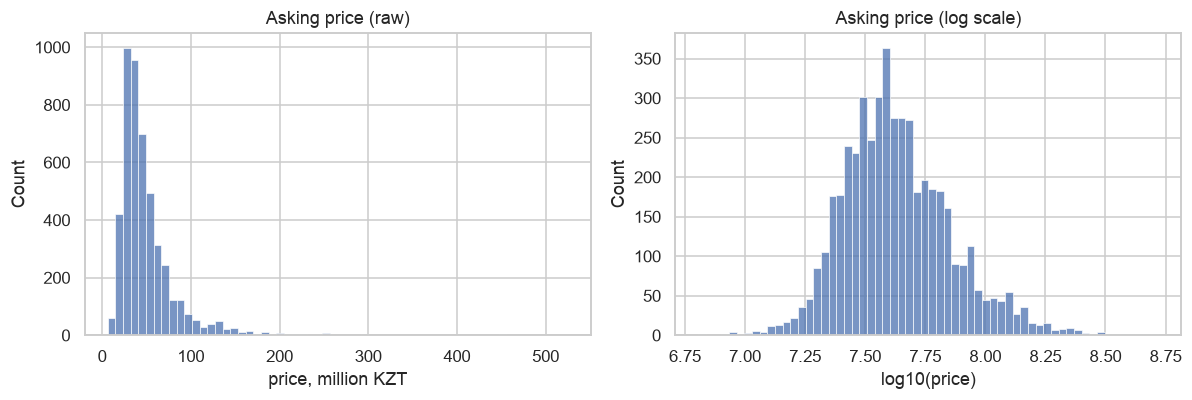

count      0.0 M
mean      50.3 M
std       36.1 M
min        6.4 M
5%        20.5 M
25%       30.0 M
50%       40.5 M
75%       58.0 M
95%      115.0 M
99%      193.9 M
max      525.0 M


In [8]:
# Plot 1 — target distribution: raw vs log
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
sns.histplot(clean["price"] / 1e6, bins=60, ax=ax[0]); ax[0].set_xlabel("price, million KZT"); ax[0].set_title("Asking price (raw)")
sns.histplot(np.log10(clean["price"]), bins=60, ax=ax[1]); ax[1].set_xlabel("log10(price)"); ax[1].set_title("Asking price (log scale)")
plt.tight_layout(); plt.savefig(FIG / "01_price_distribution.png", bbox_inches="tight"); plt.show()
print(clean["price"].describe(percentiles=[.05, .25, .5, .75, .95, .99]).apply(lambda v: f"{v/1e6:,.1f} M").to_string())

**Reading plot 1.** The raw price is strongly right-skewed: half of the ads are below the median shown above but the top 1 % go several times higher. A linear model fitted to the raw price would spend its capacity on a few luxury apartments and the squared-error metric would be dominated by them.
**Decision:** all models are trained on `log(price)` (`TransformedTargetRegressor`) and predictions are transformed back to KZT before any metric is computed. The main metric MAE is computed in KZT, not in log units.

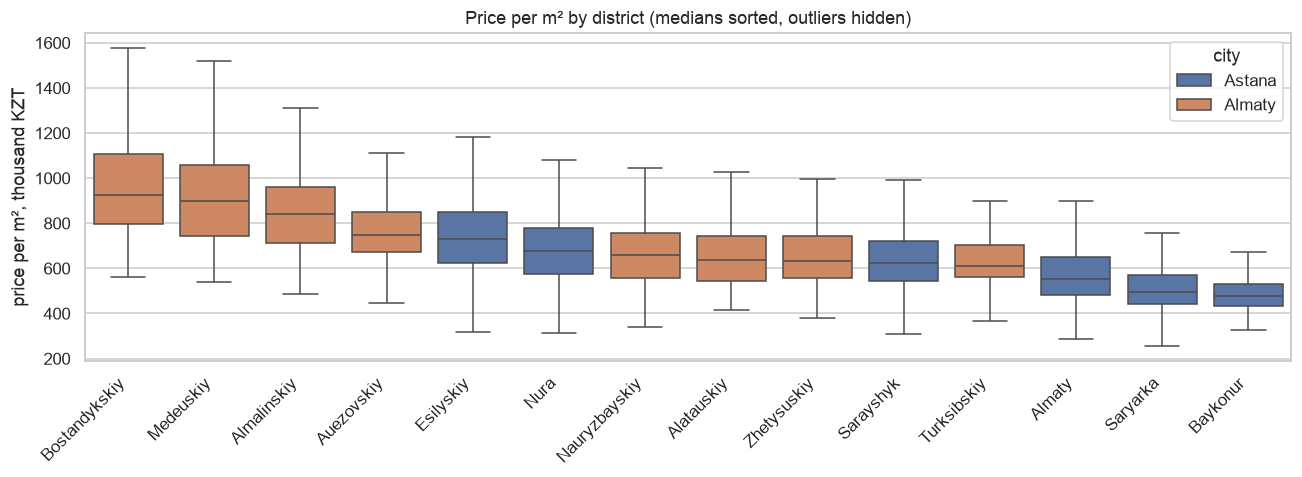

city
Almaty    743.0
Astana    639.0


In [9]:
# Plot 2 — price per m² by district and city
order = clean.groupby(["city", "district"])["price_m2"].median().sort_values(ascending=False).reset_index()
fig, ax = plt.subplots(figsize=(12, 4.5))
sns.boxplot(data=clean, x="district", y=clean["price_m2"] / 1e3, hue="city", order=order["district"].unique(), showfliers=False, ax=ax)
ax.set_ylabel("price per m², thousand KZT"); ax.set_xlabel(""); ax.set_title("Price per m² by district (medians sorted, outliers hidden)")
plt.xticks(rotation=45, ha="right"); plt.tight_layout(); plt.savefig(FIG / "02_price_m2_by_district.png", bbox_inches="tight"); plt.show()
print(clean.groupby("city")["price_m2"].median().div(1e3).round(0).rename("median price/m², kKZT").to_string())

**Reading plot 2.** Location is a first-order factor: the median price per m² differs by a factor of about two between the cheapest and the most expensive districts, and Almaty is more expensive than Astana at the same district rank. The within-district spread is still large, so district alone does not settle the price.
**Decision:** `city` and `district` stay as categorical features, and the *district-median price per m²* becomes our domain baseline (section 6.2): any real model has to beat it.

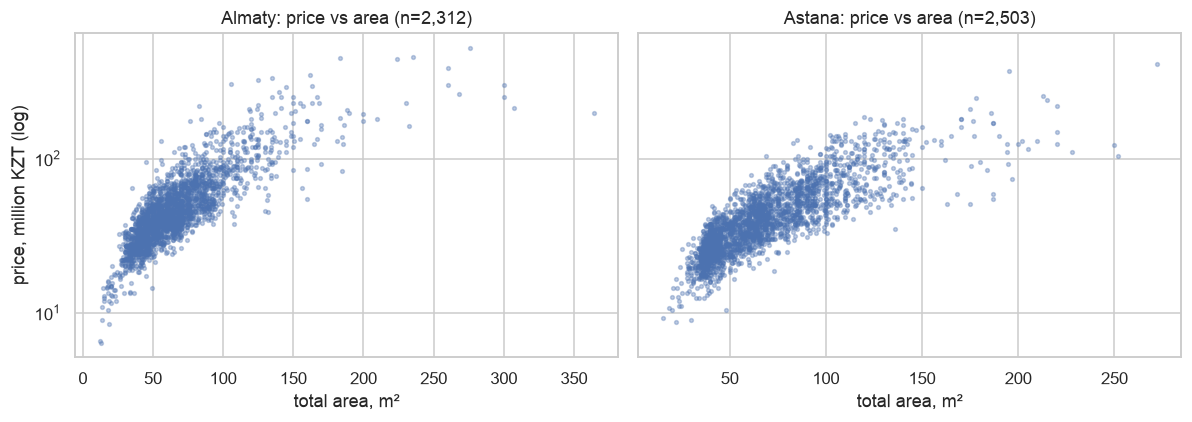

Spearman corr(area, price): 0.825


In [10]:
# Plot 3 — price vs area, by city
fig, ax = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for a, (city, g) in zip(ax, clean.groupby("city")):
    a.scatter(g["area"], g["price"] / 1e6, s=6, alpha=.35)
    a.set_title(f"{city}: price vs area (n={len(g):,})"); a.set_xlabel("total area, m²"); a.set_yscale("log")
ax[0].set_ylabel("price, million KZT (log)")
plt.tight_layout(); plt.savefig(FIG / "03_price_vs_area.png", bbox_inches="tight"); plt.show()
print("Spearman corr(area, price):", clean[["area", "price"]].corr("spearman").iloc[0, 1].round(3))

**Reading plot 3.** Price grows with area roughly multiplicatively (a straight band on the log axis), but the band is wide: at 60 m² prices span a factor of three. The spread is wider in Almaty, where old low-rise housing and new premium buildings coexist in the same area range.
**Decision:** area is the strongest single predictor. Because the target is modelled on the log scale, the linear models receive **log(area)** as well as area (a straight line in log–log space means price ∝ area^β; with raw area only, a log-price model would assume price ∝ e^area and explode for large apartments). The wide band shows that non-linear interactions (area × location × building age) matter, which is the reason to include KNN and a Decision Tree alongside the linear models.

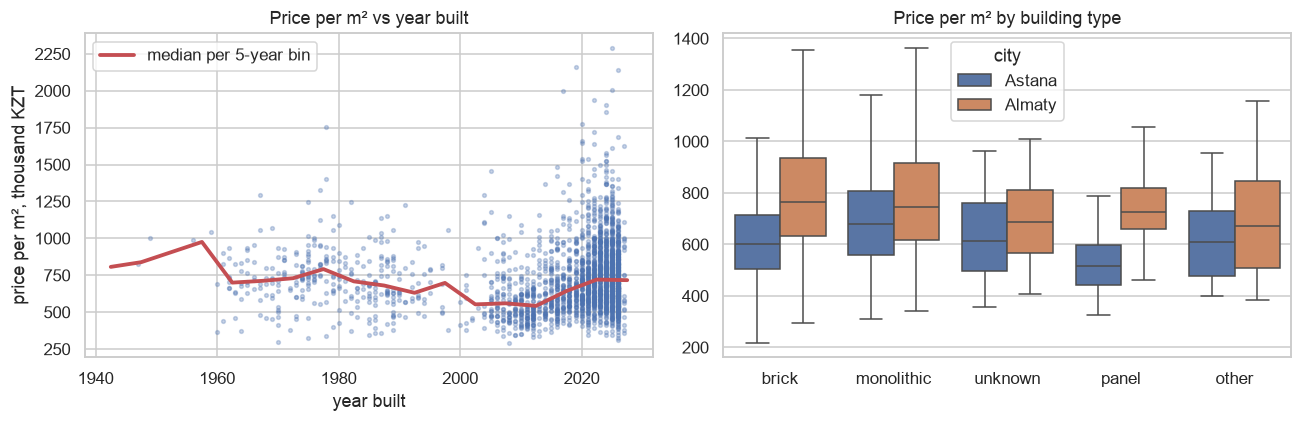

missing year_built: 0.0%


In [11]:
# Plot 4 — price per m² vs year built and building type
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
g = clean.dropna(subset=["year_built"])
gs = g.sample(min(2500, len(g)), random_state=SEED)
ax[0].scatter(gs["year_built"], gs["price_m2"] / 1e3, s=6, alpha=.3)
med = g.groupby((g["year_built"] // 5) * 5)["price_m2"].median() / 1e3   # median per 5-year bin
ax[0].plot(med.index + 2.5, med.values, color="C3", lw=2.5, label="median per 5-year bin"); ax[0].legend()
ax[0].set_xlabel("year built"); ax[0].set_ylabel("price per m², thousand KZT"); ax[0].set_title("Price per m² vs year built")
sns.boxplot(data=clean, x="building_type", y=clean["price_m2"] / 1e3, hue="city", showfliers=False, ax=ax[1])
ax[1].set_ylabel(""); ax[1].set_xlabel(""); ax[1].set_title("Price per m² by building type")
plt.tight_layout(); plt.savefig(FIG / "04_year_building_type.png", bbox_inches="tight"); plt.show()
print("missing year_built:", f"{clean.year_built.isna().mean():.1%}")

**Reading plot 4.** Price per m² is not monotonic in the year built: Soviet-era brick and panel housing (1960–1990) is cheap, buildings from the 2000s are in between, and apartments built after ~2018 are the most expensive per m². Panel houses are cheapest in both cities.
**Decision:** keep `year_built` as a number *and* `building_type` as a category; because the relation is U-shaped rather than linear, we expect the tree and KNN to use it better than the linear models, which we check in the error analysis. The share of missing years is noted above and handled by median imputation plus an indicator.

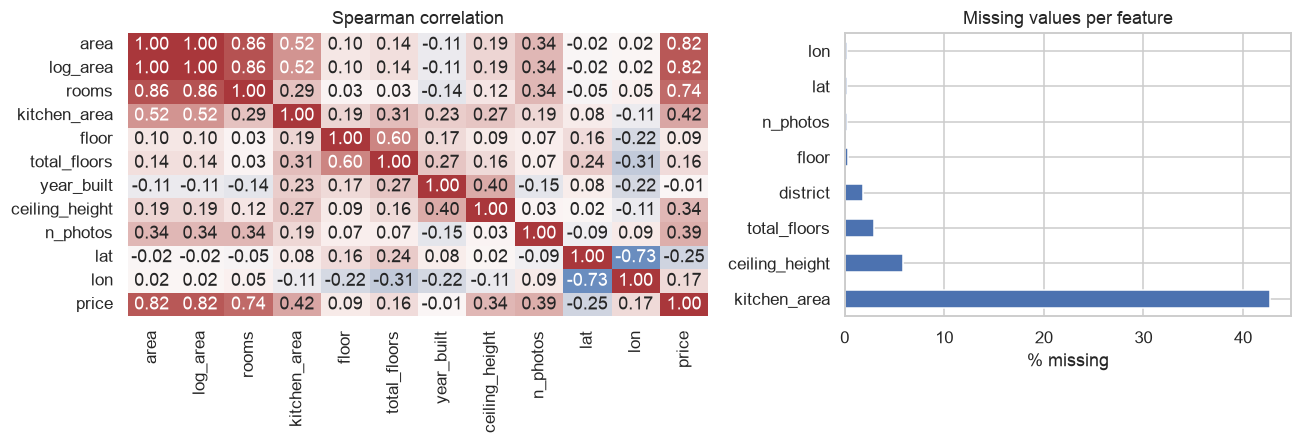

In [12]:
# Plot 5 — correlations between numeric features and the target, and missingness
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1.3, 1]})
corr = clean[NUM + ["price"]].corr("spearman")
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0, ax=ax[0], cbar=False); ax[0].set_title("Spearman correlation")
miss = clean[FEATURES].isna().mean().sort_values(ascending=False) * 100
miss[miss > 0].plot.barh(ax=ax[1]); ax[1].set_xlabel("% missing"); ax[1].set_title("Missing values per feature")
plt.tight_layout(); plt.savefig(FIG / "05_corr_missing.png", bbox_inches="tight"); plt.show()

**Reading plot 5.** `area`, `rooms` and `kitchen_area` are strongly correlated with each other (they describe the same thing), and `floor` with `total_floors`. Multicollinearity does not hurt the predictions of ordinary least squares much, but it makes its coefficients unstable, which is the reason to include **Ridge** (and Lasso as a feature-selecting variant) in the comparison. Several fields are missing for a sizeable share of ads.
**Decision:** median imputation with a *missing indicator* for numeric fields, an explicit `unknown` level for categories. Both are fitted on the training fold only.

## 6. Modelling workflow

### 6.1 Fixed split
80 / 20 train/test split with `random_state=42`. The list of test ids is saved to `data/clean/split_ids.csv` and will be reused unchanged at the Endterm and the Final.

In [13]:
from sklearn.model_selection import train_test_split, KFold, cross_validate, cross_val_predict
X = clean[FEATURES].copy()
for c in BOOL: X[c] = X[c].astype(int)
for c in CAT:  X[c] = X[c].astype(object).where(X[c].notna(), "unknown").astype(str)   # an explicit 'unknown' level, no NaN in categories
for c in NUM:  X[c] = pd.to_numeric(X[c], errors="coerce").astype("float64")     # plain numpy floats (NaN, not pd.NA) for scikit-learn
y = clean[TARGET].to_numpy(dtype="float64")
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)
Path("data/clean").mkdir(exist_ok=True)
pd.DataFrame({"id": clean.loc[X_test.index, "id"].values, "split": "test"}).to_csv("data/clean/split_ids.csv", index=False)
clean.to_csv("data/clean/krisha_apartments_clean.csv", index=False)
print(f"train {len(X_train):,} rows, test {len(X_test):,} rows; test ids saved")
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)

train 3,852 rows, test 963 rows; test ids saved


### 6.2 Preprocessing pipeline and baselines
All preprocessing lives inside a scikit-learn `Pipeline`, so it is fitted on the training part of every fold only:
- numeric: median imputation + missing indicator, then `StandardScaler` (needed for KNN, Ridge and Lasso; harmless for the tree);
- categorical: `OneHotEncoder(handle_unknown="ignore")`.

Two baselines:
1. **`DummyRegressor(median)`** — predicts the training median price. The floor every model must clear.
2. **District median price per m² × area** — the "domain" baseline from our registration: what a person would do with a price-per-m² table. Implemented as an estimator that learns the medians from the training fold only.

In [14]:
from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

pre = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median", add_indicator=True)), ("sc", StandardScaler())]), NUM + BOOL),
    ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=10), CAT),
])
# a second preprocessor for the "size + location" KNN: only the columns a Euclidean distance should compare
KNN_NUM = ["log_area", "area", "rooms", "floor", "total_floors", "year_built", "lat", "lon"]
pre_knn = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median", add_indicator=True)), ("sc", StandardScaler())]), KNN_NUM),
    ("city", OneHotEncoder(handle_unknown="ignore"), ["city", "district"]),
])

class DistrictMedianPerM2(BaseEstimator, RegressorMixin):
    # price = median(price/m² in the same city+district on TRAIN) * area ; falls back to the city median
    def fit(self, X, y):
        t = X[["city", "district", "area"]].copy(); t["pm2"] = y / t["area"]
        self.med_ = t.groupby(["city", "district"])["pm2"].median().to_dict()
        self.city_med_ = t.groupby("city")["pm2"].median().to_dict()
        self.global_med_ = float(t["pm2"].median()); return self
    def predict(self, X):
        pm2 = [self.med_.get((c, d), self.city_med_.get(c, self.global_med_)) for c, d in zip(X["city"], X["district"])]
        return np.asarray(pm2) * X["area"].values

def logged(est):
    return TransformedTargetRegressor(regressor=Pipeline([("pre", pre), ("model", est)]), func=np.log, inverse_func=np.exp)

def mdape(y_true, y_pred): return float(np.median(np.abs(y_pred - y_true) / y_true) * 100)
scoring = {"MAE": "neg_mean_absolute_error", "RMSE": "neg_root_mean_squared_error", "R2": "r2",
           "MdAPE": lambda est, X, y: -mdape(y, est.predict(X))}

### 6.3 Choosing the main hyperparameters on purpose
Before the final comparison we sweep the one hyperparameter that matters most for each model with the same 5-fold CV on the training set: `alpha` for Ridge and Lasso, `k` for KNN, `max_depth` for the tree. We pick the value with the best CV MAE; the plot shows that the choice is not arbitrary.

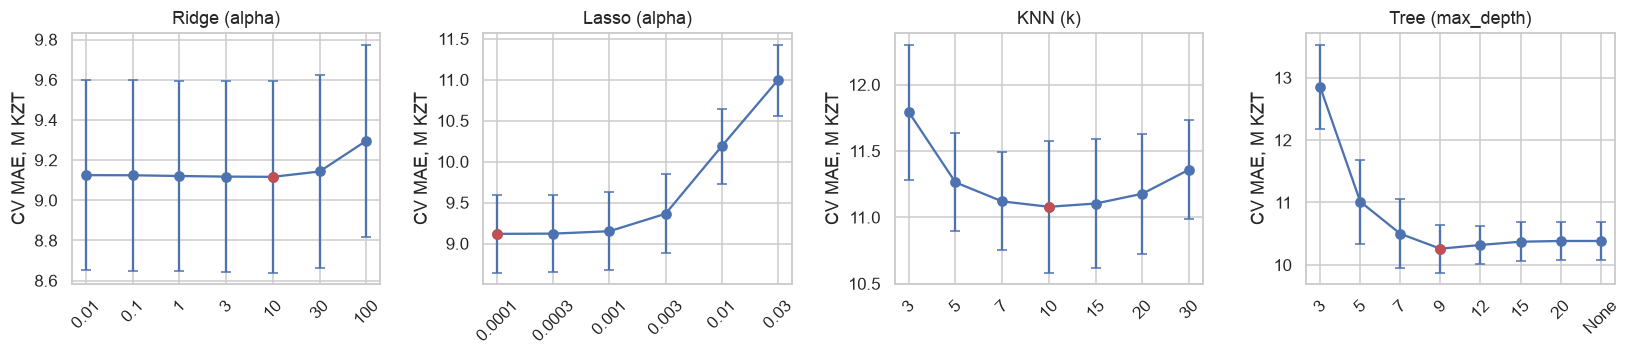

chosen: {'Ridge (alpha)': 10, 'Lasso (alpha)': 0.0001, 'KNN (k)': 10, 'Tree (max_depth)': 9}


In [15]:
def cv_mae(est, X, y):
    r = cross_validate(est, X, y, cv=cv, scoring="neg_mean_absolute_error", n_jobs=-1)
    return -r["test_score"].mean() / 1e6, r["test_score"].std() / 1e6

sweeps = {
    "Ridge (alpha)": ([0.01, 0.1, 1, 3, 10, 30, 100], lambda a: logged(Ridge(alpha=a))),
    "Lasso (alpha)": ([1e-4, 3e-4, 1e-3, 3e-3, 1e-2, 3e-2], lambda a: logged(Lasso(alpha=a, max_iter=20000))),
    "KNN (k)":       ([3, 5, 7, 10, 15, 20, 30], lambda k: logged(KNeighborsRegressor(n_neighbors=k, weights="distance"))),
    "Tree (max_depth)": ([3, 5, 7, 9, 12, 15, 20, None], lambda dpt: logged(DecisionTreeRegressor(max_depth=dpt, min_samples_leaf=5, random_state=SEED))),
}
best = {}
fig, axes = plt.subplots(1, 4, figsize=(15, 3.4))
for ax, (name, (grid, make)) in zip(axes, sweeps.items()):
    res = [cv_mae(make(v), X_train, y_train) for v in grid]
    means = [m for m, s in res]; labels = [str(v) for v in grid]
    ax.errorbar(range(len(grid)), means, yerr=[s for m, s in res], marker="o", capsize=3)
    ax.set_xticks(range(len(grid))); ax.set_xticklabels(labels, rotation=45); ax.set_title(name); ax.set_ylabel("CV MAE, M KZT")
    i = int(np.argmin(means)); best[name] = grid[i]; ax.scatter([i], [means[i]], color="C3", zorder=5)
plt.tight_layout(); plt.savefig(FIG / "06_hyperparameter_sweeps.png", bbox_inches="tight"); plt.show()
print("chosen:", best)

### 6.4 The models and why each one is here

| Model | Why it is in the comparison |
|---|---|
| Dummy (median) | sanity floor |
| District median price/m² | what a realtor does by hand; the bar to beat |
| Linear Regression (on log price) | the simplest explainable model; plot 3 showed a log-linear relation with area |
| Ridge | same model with L2 shrinkage — plot 5 showed correlated features (area/rooms/kitchen, floor/total floors) |
| Lasso | L1 shrinkage drops useless one-hot levels (there are many district × attribute levels) |
| KNN (scaled, distance-weighted) | "similar apartments nearby cost similar money" — uses lat/lon and area directly; needs scaling, which the pipeline guarantees |
| KNN on size + location only | the same idea with a distance that makes sense: only area, rooms, floors, year, coordinates and city, so that ~50 one-hot columns do not drown the geography |
| Decision Tree | captures the non-monotonic year effect (plot 4) and interactions without feature engineering |

All models are compared with the same **5-fold cross-validation on the training set** (mean ± std) and then evaluated **once** on the untouched test set.

In [16]:
models = {
    "Dummy (median)":            Pipeline([("pre", pre), ("model", DummyRegressor(strategy="median"))]),
    "District median price/m²":  DistrictMedianPerM2(),
    "Linear Regression":         logged(LinearRegression()),
    f"Ridge (alpha={best['Ridge (alpha)']})":   logged(Ridge(alpha=best["Ridge (alpha)"])),
    f"Lasso (alpha={best['Lasso (alpha)']})":   logged(Lasso(alpha=best["Lasso (alpha)"], max_iter=20000)),
    f"KNN (k={best['KNN (k)']}, distance)":     logged(KNeighborsRegressor(n_neighbors=best["KNN (k)"], weights="distance")),
    f"KNN size+location (k={best['KNN (k)']})": TransformedTargetRegressor(regressor=Pipeline([("pre", pre_knn), ("model", KNeighborsRegressor(n_neighbors=best["KNN (k)"], weights="distance"))]), func=np.log, inverse_func=np.exp),
    f"Decision Tree (depth={best['Tree (max_depth)']})": logged(DecisionTreeRegressor(max_depth=best["Tree (max_depth)"], min_samples_leaf=5, random_state=SEED)),
}
rows, fitted, test_pred = [], {}, {}
for name, est in models.items():
    r = cross_validate(est, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    est.fit(X_train, y_train); p = est.predict(X_test); fitted[name] = est; test_pred[name] = p
    rows.append({"model": name,
                 "CV MAE (M KZT)": f"{-r['test_MAE'].mean()/1e6:.2f} ± {r['test_MAE'].std()/1e6:.2f}",
                 "CV MdAPE %": f"{-r['test_MdAPE'].mean():.1f} ± {r['test_MdAPE'].std():.1f}",
                 "CV R²": f"{r['test_R2'].mean():.3f} ± {r['test_R2'].std():.3f}",
                 "Test MAE (M KZT)": mean_absolute_error(y_test, p) / 1e6,
                 "Test RMSE (M KZT)": root_mean_squared_error(y_test, p) / 1e6,
                 "Test MdAPE %": mdape(y_test, p),
                 "Test R²": r2_score(y_test, p)})
results = pd.DataFrame(rows).set_index("model").round(3)
results.to_csv("figures/results_table.csv")
display(results)

,CV MAE (M KZT),CV MdAPE %,CV R²,Test MAE (M KZT),Test RMSE (M KZT),Test MdAPE %,Test R²
model,,,,,,,
Dummy (median),20.80 ± 0.62,32.2 ± 1.5,-0.079 ± 0.009,20.402,37.677,33.058,-0.067
District median price/m²,10.47 ± 0.53,14.6 ± 0.5,0.686 ± 0.038,9.945,20.290,14.346,0.691
Linear Regression,9.12 ± 0.47,12.1 ± 0.4,0.748 ± 0.043,8.650,19.416,11.343,0.717
Ridge (alpha=10),9.12 ± 0.48,12.0 ± 0.3,0.746 ± 0.043,8.660,19.512,11.448,0.714
Lasso (alpha=0.0001),9.12 ± 0.47,12.1 ± 0.4,0.748 ± 0.043,8.629,19.328,11.321,0.719
"KNN (k=10, distance)",11.08 ± 0.50,15.8 ± 0.8,0.644 ± 0.038,10.666,21.008,16.108,0.668
KNN size+location (k=10),10.14 ± 0.63,13.7 ± 0.2,0.681 ± 0.051,9.703,19.382,13.432,0.718
Decision Tree (depth=9),10.26 ± 0.38,13.4 ± 0.4,0.672 ± 0.048,9.301,18.304,12.704,0.748


## 7. Results and error analysis

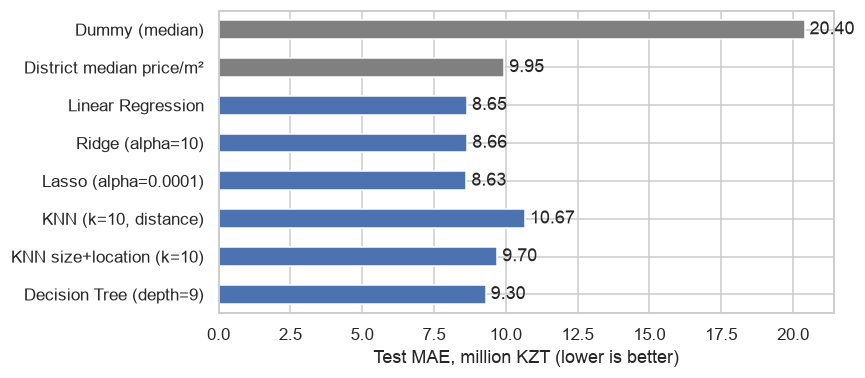

best model on test: Lasso (alpha=0.0001)


In [17]:
fig, ax = plt.subplots(figsize=(8, 3.6))
results["Test MAE (M KZT)"].plot.barh(ax=ax, color=["grey", "grey"] + ["C0"] * (len(results) - 2))
ax.invert_yaxis(); ax.set_xlabel("Test MAE, million KZT (lower is better)"); ax.set_ylabel("")
for i, v in enumerate(results["Test MAE (M KZT)"]): ax.text(v, i, f" {v:.2f}", va="center")
plt.tight_layout(); plt.savefig(FIG / "07_test_mae.png", bbox_inches="tight"); plt.show()
best_name = results["Test MAE (M KZT)"].idxmin(); print("best model on test:", best_name)

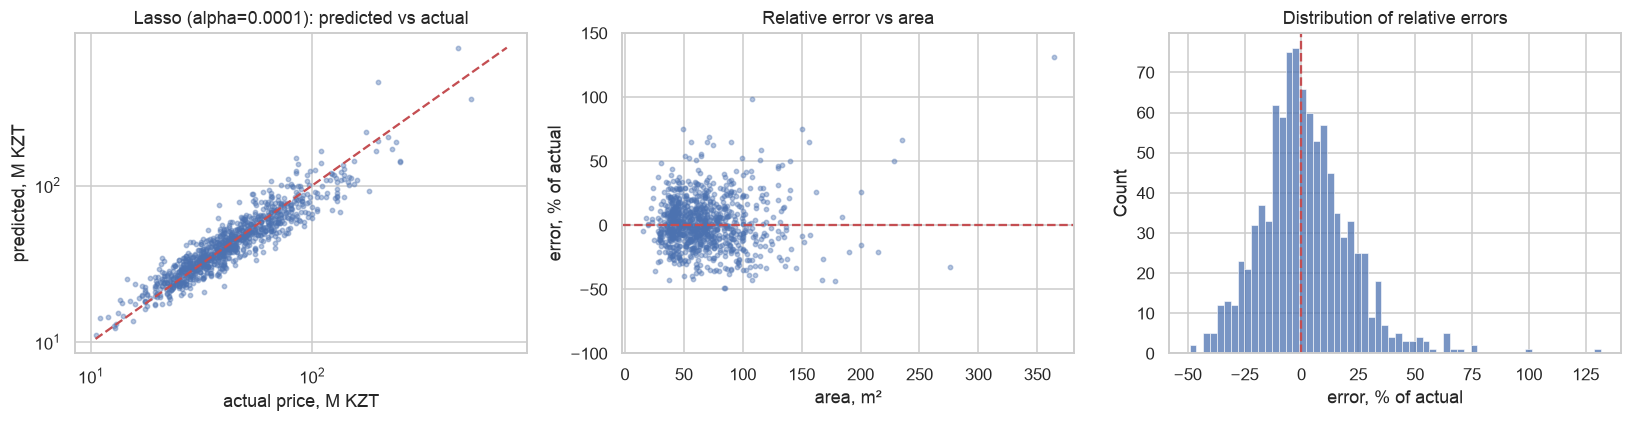

share of test ads within ±10 %: 44.7%   within ±20 %: 72.6%


In [18]:
# Residual plots for the best model
p = test_pred[best_name]; resid = p - y_test; rel = resid / y_test * 100
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].scatter(y_test / 1e6, p / 1e6, s=8, alpha=.4); lim = [min(y_test.min(), p.min()) / 1e6, max(y_test.max(), p.max()) / 1e6]
ax[0].plot(lim, lim, "r--"); ax[0].set_xscale("log"); ax[0].set_yscale("log"); ax[0].set_xlabel("actual price, M KZT"); ax[0].set_ylabel("predicted, M KZT"); ax[0].set_title(f"{best_name}: predicted vs actual")
ax[1].scatter(X_test["area"], rel, s=8, alpha=.4); ax[1].axhline(0, color="r", ls="--"); ax[1].set_xlabel("area, m²"); ax[1].set_ylabel("error, % of actual"); ax[1].set_title("Relative error vs area"); ax[1].set_ylim(-100, 150)
sns.histplot(rel.clip(-100, 150), bins=60, ax=ax[2]); ax[2].axvline(0, color="r", ls="--"); ax[2].set_xlabel("error, % of actual"); ax[2].set_title("Distribution of relative errors")
plt.tight_layout(); plt.savefig(FIG / "08_residuals.png", bbox_inches="tight"); plt.show()
print(f"share of test ads within ±10 %: {(np.abs(rel) <= 10).mean():.1%}   within ±20 %: {(np.abs(rel) <= 20).mean():.1%}")

In [19]:
# Where does the error concentrate? by city, rooms, price band, seller type
err = clean.loc[X_test.index, ["city", "district", "rooms", "area", "price", "seller_type", "building_type", "year_built", "condition", "description", "has_detail"]].copy()
err["pred"] = p; err["abs_err_M"] = np.abs(resid) / 1e6; err["ape_%"] = np.abs(rel)
err["price_band"] = pd.cut(err["price"] / 1e6, [0, 20, 35, 50, 80, 150, 1e4], labels=["<20M", "20–35M", "35–50M", "50–80M", "80–150M", ">150M"])
tabs = []
for col in ["city", "price_band", "rooms", "seller_type", "has_detail"]:
    t = err.groupby(col, observed=True).agg(n=("pred", "size"), MAE_M=("abs_err_M", "mean"), MdAPE=("ape_%", "median")).round(1)
    t.index = [f"{col}={i}" for i in t.index]; tabs.append(t)
display(pd.concat(tabs))

,n,MAE_M,MdAPE
city=Almaty,463,9.7,11.0
city=Astana,500,7.6,11.5
price_band=<20M,45,2.8,13.6
price_band=20–35M,320,3.7,9.9
price_band=35–50M,275,5.3,9.8
price_band=50–80M,220,9.8,12.3
price_band=80–150M,88,23.2,21.2
price_band=>150M,15,90.4,32.0
rooms=1.0,200,3.4,10.1
rooms=2.0,389,6.2,11.3


In [20]:
# the 8 worst test errors with the seller's own words
pd.set_option("display.max_colwidth", 140)
worst = err.sort_values("ape_%", ascending=False).head(8)
worst["description"] = worst["description"].astype("string").str.replace(r"\s+", " ", regex=True).str.slice(0, 140)
display(worst[["city", "district", "rooms", "area", "year_built", "condition", "price", "pred", "ape_%", "description"]]
        .assign(price=lambda t: (t["price"] / 1e6).round(1), pred=lambda t: (t["pred"] / 1e6).round(1)))

,city,district,rooms,area,year_built,condition,price,pred,ape_%,description
4415,Almaty,Medeuskiy,5.0,364.0,2011.0,fresh_renovation,197.6,457.8,131.703152,Отличный трёх уровненный пентхаус в элитном центре Алматы и одновременно над городом! Все уровни полноценные (нет цокольных). Первый уро...
1588,Almaty,Nauryzbayskiy,3.0,108.0,2012.0,fresh_renovation,38.0,75.6,98.847082,Представляем Вашему вниманию 3-комнатную просторную квартиру в Жилом комплексе «Примьера» Расположение Находящийся по ул Жуалы рядом общ...
4490,Almaty,Turksibskiy,2.0,49.0,1970.0,unknown,14.5,25.4,75.469111,"Пластиковые окна, не угловая, тихий двор. Внимание! Продаётся 2х комнатная квартира в Нижней пятилетки. ✅️Квартира не угловая ✅️Комнаты ..."
1392,Almaty,Medeuskiy,4.0,150.0,2023.0,good,85.0,148.9,75.148511,"Продается 3-уровневый таунхаус, 4 раздельные комнаты, на 22 сотках земли, клубный дом находится в ЖК Family village. Построен по индивид..."
2231,Almaty,Almalinskiy,3.0,71.0,2012.0,fresh_renovation,46.5,78.4,68.571311,"Продается просторная евро 3-комнатная квартира — 71 м² ✨ Светлая, уютная и функциональная квартира для комфортной жизни всей семьи. Преи..."
4706,Almaty,Medeuskiy,4.0,235.0,2022.0,fresh_renovation,455.0,758.6,66.719080,"4-комнатная квартира площадью 235 м² в одном из самых востребованных районов Алматы — Горном Гиганте, в элитном жилом комплексе с закрыт..."
350,Astana,Almaty,2.0,70.0,2015.0,good,37.5,61.9,65.013778,Удобно под коммерцию. Продаётся просторная 2-комнатная квартира 70 м² — отличный вариант для жизни или под коммерцию! Квартира в доме 20...
1345,Almaty,Medeuskiy,3.0,90.0,2025.0,unknown,53.5,88.2,64.906735,• Продается евро 3-комнатная квартира в ЖК Arman City • Расположение: Медеуский район • Этаж: 2 из 6 • Год постройки: 2025 • Класс: Комф...


**What the error analysis shows.**
- *Predicted vs actual* follows the diagonal over two orders of magnitude; the relative-error histogram is centred on zero with a long **positive** tail: the model over-estimates far more often than it under-estimates by a large margin.
- *By price band*: the median error is about 10 % for the mass market (20–50 M KZT) and grows to about 21 % above 80 M and ~30 % above 150 M, where there are only a few dozen training ads and the price depends on things we do not observe (view, finishing, the exact house).
- *By rooms / area*: 1-room apartments are predicted best (MdAPE ≈ 10 %), 4+ rooms worst; errors widen above ~120 m² simply because such ads are rare.
- *By source of the row*: after the second collection run only a handful of test ads are card-only, so this split is no longer informative. In the first run (4 October), when half of the rows were card-only, ads with coordinates were predicted about one point better (MdAPE 11.8 % vs 13.0 %), which is why we completed the collection.
- *Worst cases* (table above) are almost all **ads that are cheap for a reason stated only in the text**: "только наличный расчёт" (cash only), "документы в конце года" (unfinished building, no title yet), assignment-of-rights sales in 2025–2026 buildings, or an object that is not really an apartment (a townhouse on a land plot). The structured fields describe a normal new apartment, so the model prices it as one. This is exactly the information the Final-stage text features should add.

### 7.1 What the best model learned, and saving it
The linear model on log price is multiplicative: a coefficient *c* on a one-hot column means the price is multiplied by e^c, all else equal. The table shows the strongest effects. The fitted model is saved with joblib so that the Endterm can start from it and the Final can wrap it in a local app.

In [21]:
import joblib
best_est = fitted[best_name]
Path("models").mkdir(exist_ok=True)
joblib.dump(best_est, "models/best_model.joblib")
# coefficients of the linear model (inside TransformedTargetRegressor -> Pipeline)
try:
    pipe = best_est.regressor_
    names = pipe.named_steps["pre"].get_feature_names_out()
    coefs = pipe.named_steps["model"].coef_
    ct = pd.DataFrame({"feature": names, "coef_log": coefs})
    ct["effect_%"] = (np.exp(ct["coef_log"]) - 1) * 100
    ct = ct[~ct["feature"].str.contains("missingindicator")]
    print("Strongest effects (one-hot: price multiplier vs the reference level; numeric: per +1 std):")
    display(pd.concat([ct.nlargest(10, "coef_log"), ct.nsmallest(10, "coef_log")]).round(3).reset_index(drop=True))
except Exception as e:
    print("coefficient table not available for this model:", e)
# a prediction for one new listing
example = pd.DataFrame([{"area": 62.0, "log_area": np.log(62.0), "rooms": 2, "kitchen_area": 10.0, "floor": 5, "total_floors": 9, "year_built": 2019,
                         "ceiling_height": 2.8, "n_photos": 12, "lat": 51.128, "lon": 71.43, "city": "Astana", "district": "Esilyskiy",
                         "building_type": "monolithic", "condition": "fresh_renovation", "bathroom": "separate", "furnished": "partly",
                         "balcony": "has", "parking": "parking", "former_dorm": "no", "seller_type": "owner",
                         "has_complex": 1, "mortgaged": 0, "is_urgent": 0, "has_detail": 1}])
print(f"\nExample: 2-room, 62 m², Esil district of Astana, monolithic 2019, fresh renovation -> predicted asking price {best_est.predict(example)[0]/1e6:.1f} M KZT")
print("model saved to models/best_model.joblib")

Strongest effects (one-hot: price multiplier vs the reference level; numeric: per +1 std):


,feature,coef_log,effect_%
0,num__log_area,0.295,34.286
1,cat__district_Bostandykskiy,0.272,31.248
2,cat__district_Medeuskiy,0.256,29.183
3,cat__district_Almalinskiy,0.199,22.031
4,cat__district_Esilyskiy,0.123,13.131
5,cat__condition_fresh_renovation,0.110,11.605
6,cat__district_Auezovskiy,0.108,11.399
7,num__ceiling_height,0.083,8.706
8,cat__condition_unknown,0.065,6.689
9,num__area,0.056,5.804



Example: 2-room, 62 m², Esil district of Astana, monolithic 2019, fresh renovation -> predicted asking price 43.5 M KZT
model saved to models/best_model.joblib


## 8. Conclusions, limitations and Endterm plan

In [22]:
b = results.loc[best_name]; base = results.loc["District median price/m²"]
print(f"Best model: {best_name}")
print(f"  test MAE   {b['Test MAE (M KZT)']:.2f} M KZT  (district-median baseline {base['Test MAE (M KZT)']:.2f} M, dummy {results.loc['Dummy (median)','Test MAE (M KZT)']:.2f} M)")
print(f"  test MdAPE {b['Test MdAPE %']:.1f} %        (baseline {base['Test MdAPE %']:.1f} %)")
print(f"  test R²    {b['Test R²']:.3f}              (baseline {base['Test R²']:.3f})")
print(f"  within ±10 %: {(np.abs(rel) <= 10).mean():.0%} of test ads, within ±20 %: {(np.abs(rel) <= 20).mean():.0%}")
summary = {"raw_rows": int(n0), "clean_rows": int(len(clean)), "n_detail": int(clean["has_detail"].sum()), "n_card": int((~clean["has_detail"]).sum()), "astana": int((clean.city == "Astana").sum()), "almaty": int((clean.city == "Almaty").sum()),
           "cleaning": steps, "best_params": {k: (None if v is None else float(v)) for k, v in best.items()},
           "best_model": best_name, "best_mae": float(b["Test MAE (M KZT)"]), "best_mdape": float(b["Test MdAPE %"]), "best_r2": float(b["Test R²"]),
           "base_mae": float(base["Test MAE (M KZT)"]), "base_mdape": float(base["Test MdAPE %"]), "dummy_mae": float(results.loc["Dummy (median)", "Test MAE (M KZT)"]),
           "within10": float((np.abs(rel) <= 10).mean()), "within20": float((np.abs(rel) <= 20).mean())}
(FIG / "summary.json").write_text(json.dumps(summary, indent=2, ensure_ascii=False))

Best model: Lasso (alpha=0.0001)
  test MAE   8.63 M KZT  (district-median baseline 9.95 M, dummy 20.40 M)
  test MdAPE 11.3 %        (baseline 14.3 %)
  test R²    0.719              (baseline 0.691)
  within ±10 %: 45% of test ads, within ±20 %: 73%


1152

### Answer to the question
*See the printed numbers above; the text below is written for the values we obtained.*

With only the structured fields of a krisha.kz ad, the best Week 3–4 model (a linear model on log price with log area; Lasso, Ridge and plain least squares are within 0.03 M of each other) predicts the asking price with a **median relative error of about 11 %** and a **MAE of about 8.6 M KZT**, against 14.3 % / 9.9 M for the realtor's "district price per m² × area" rule and 33 % / 20 M for the dummy median. 73 % of test ads are within ±20 % of the prediction. For a buyer this means: an asking price more than ~20 % above the model estimate is in the upper third of comparable listings and is worth questioning; for a seller it gives a defensible starting price. The ideal goal (median error under 10 %) is **not yet reached**.

The ranking is informative in itself. The three linear models are indistinguishable: once the target and the area are on the log scale, the relation is close to linear and regularisation has nothing left to fix (the chosen alphas are small). **KNN and the single Decision Tree are behind the linear models on the main metric**, and we can say why. KNN over all ~50 scaled columns, half of them one-hot indicators, does not measure "nearby in the city"; restricting the distance to size and location (area, rooms, floors, year, coordinates, city, district) cuts its MdAPE from 16 % to 13.4 %, which confirms the diagnosis but is still behind. The tree at depth 9 comes closest (MdAPE 12.7 %) and actually has the best R² and RMSE, because it handles the expensive segment better, but it approximates the smooth area→price relation with a staircase and is the least stable model across folds. The non-linear structure we saw in the exploration (U-shaped year effect, wide band at a given area) is real, and a single tree already catches part of it — ensembles of trees are the obvious next step, which is the main argument for the Endterm plan.

### Limitations (concrete)
1. **Asking price ≠ sale price.** We model what sellers ask, not what buyers pay; a systematic premium of a few percent is invisible to us.
2. **One snapshot, one day.** All data are from 4 October 2026; prices move with the exchange rate and mortgage programmes, so the model is not valid months later without re-scraping.
3. **Seller-typed fields.** `condition`, `year_built`, `kitchen_area` are missing or wrong in a noticeable share of ads (kitchen area is absent in most ads); the worst errors above are often data errors rather than model errors.
4. **Unobserved quality.** View, floor plan, finishing quality and the exact house are not in the structured fields; the description text and photos carry them, and they are the Final-stage source.
5. **Thin tails.** Fewer than a few percent of ads are above 150 M KZT or above 150 m²; errors there are large and the model should not be used for the luxury segment.
6. **One site.** The registration named olx.kz and kn.kz as additional sources; they were not needed for the row count, so prices reflect krisha.kz's audience (mostly agents). Adding them at a later stage would test whether the model transfers across sites.

### Endterm plan (Weeks 5–8 topics), each tied to a weakness above
| Weakness in the current results | Week 5–8 topic we will apply | Why it should help |
|---|---|---|
| A single tree already has the best R² but a staircase fit and the largest fold-to-fold spread; KNN only works when the distance is restricted by hand; both are behind the linear model on MAE although the data are visibly non-linear (U-shaped year effect, area × district interactions) | **Ensembles: Random Forest and Gradient Boosting** (Week 5–6) with **hyperparameter tuning** (randomised search inside the same 5-fold CV) | Boosted trees fit smooth curves with many shallow steps and learn interactions automatically; this is the model class we expect to take MdAPE under the 10 % goal |
| The error grows with price and with rooms: the expensive segment behaves differently, but one global model treats all ads alike; we also never defined "market segments" | **Clustering (K-Means / DBSCAN on area, rooms, year, price per m², and lat/lon where present) and PCA** (Week 7) | Segment id as a feature and a separate look at the luxury cluster; PCA to see how many independent dimensions the one-hot district/attribute columns really carry and to feed KNN a compact space |
| Linear model cannot bend; the tree bends only in steps | **Neural network (MLP regressor)** on the scaled features (Week 8) | A small MLP learns smooth interactions between area, age, district and coordinates; it will be compared with the boosted trees on the *same* saved split |
| Worst errors come from information that is only in the text ("cash only", "no documents yet", townhouse) | (Final) TF-IDF / embeddings of `description` | planned for the Final, data already collected |

The split saved in `data/clean/split_ids.csv` will be reused unchanged, so the Endterm numbers are directly comparable with this table.

## 9. Contributions and AI tools
**Rakhat Balgabekov** — chose and checked the source, wrote the scraper stage 1 (search pages), the data card and the cleaning rules, prepared the slides on question/data/preparation.
**Aitbek Kaiyrbekuly** — wrote the scraper stage 2 (ad pages) and the parsing code, built the pipeline, the baselines, the cross-validation and the error analysis, prepared the slides on models/results.
Both: exploration plots, conclusions and the Endterm plan were discussed and written together; both can explain every part.

**AI tools.**